<a href="https://colab.research.google.com/github/AmitabhTS/AML-LAB-EXPERIMENTS/blob/main/AMLEXP11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Duplicate records: 0
Numerical features:
['ID', 'Year_Birth', 'Income', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response']

Categorical features:
['Education', 'Marital_Status', 'Dt_Customer']

Missing-value summary:
ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases 

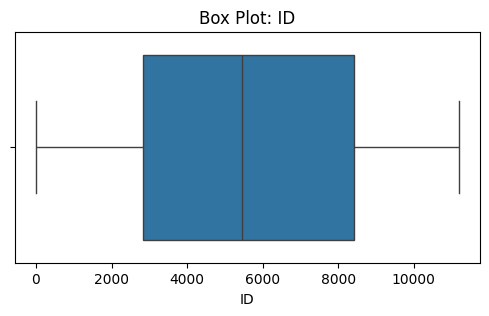

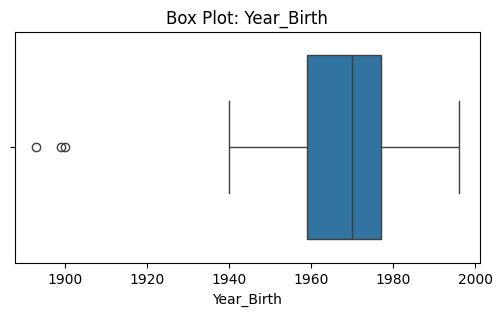

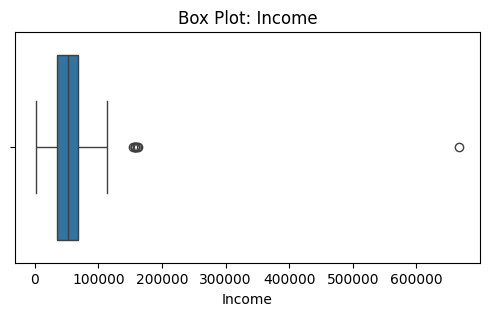

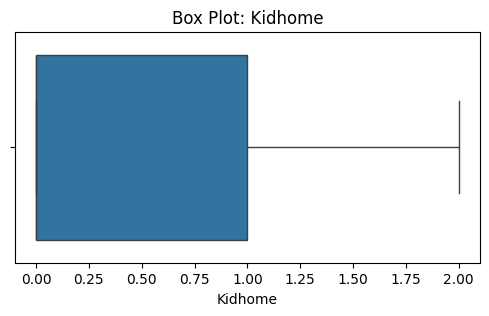

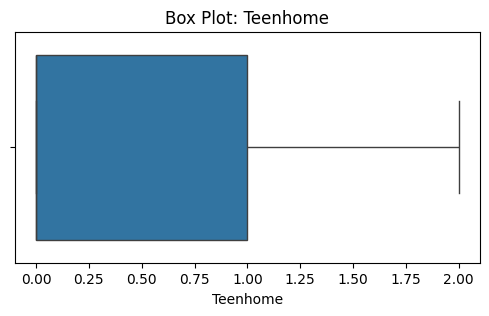

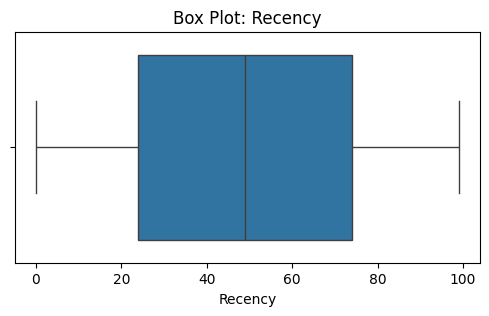

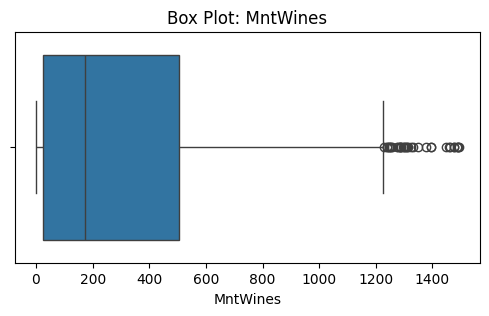

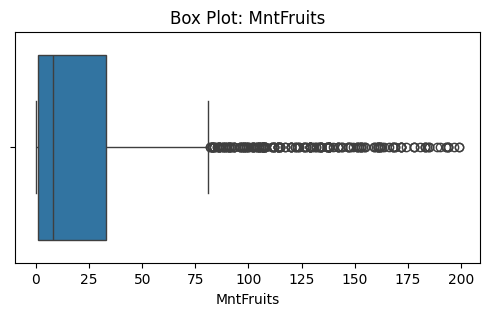

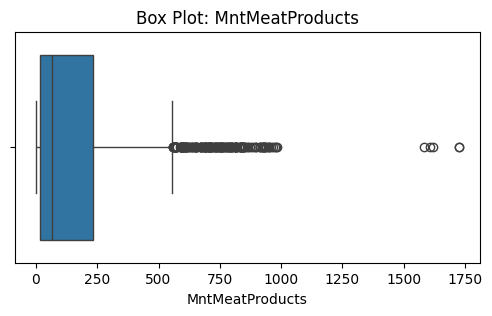

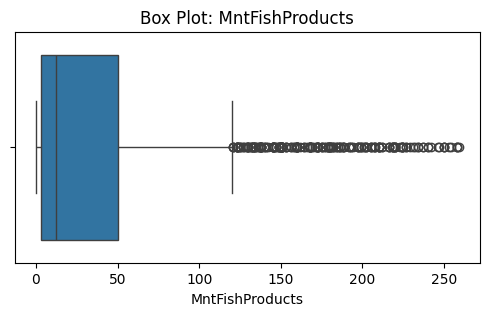

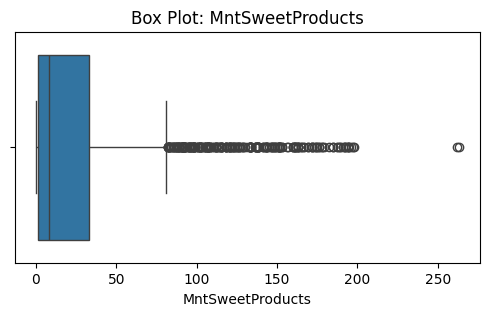

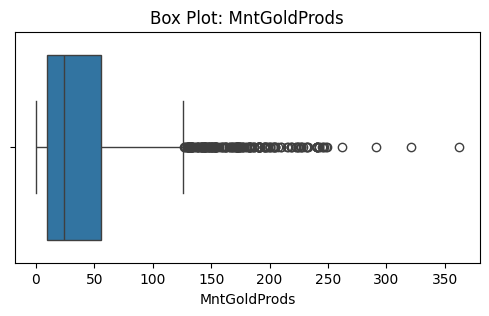

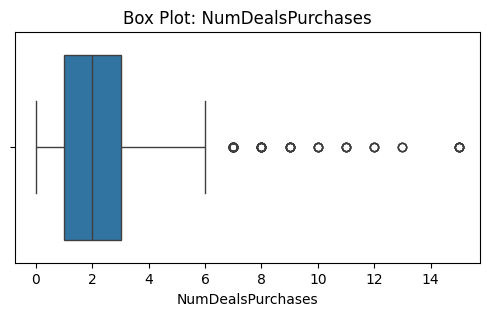

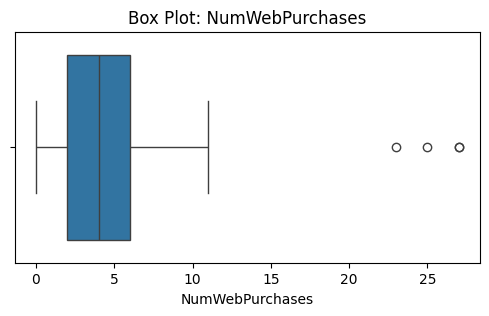

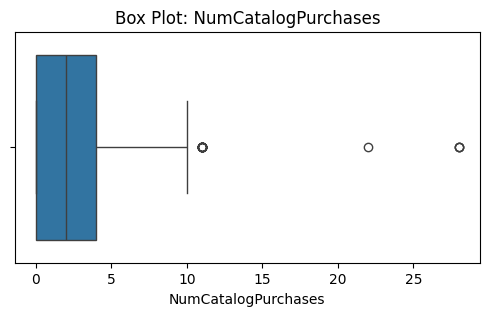

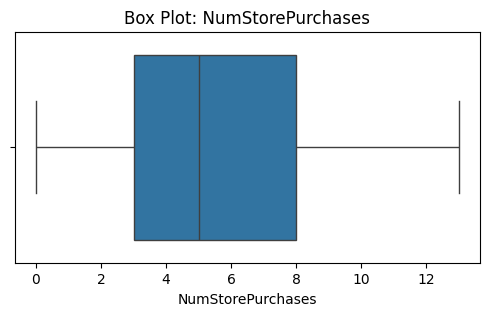

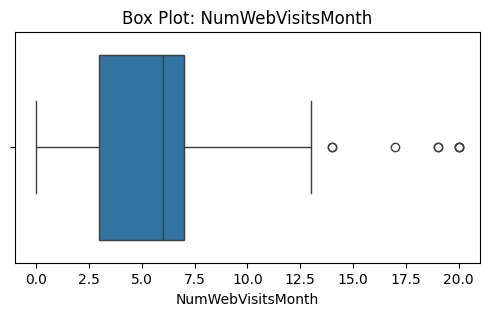

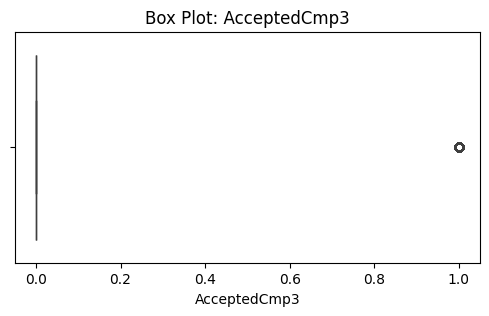

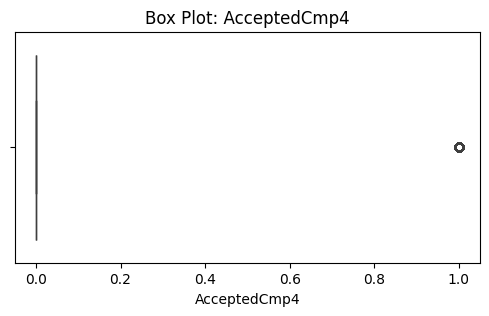

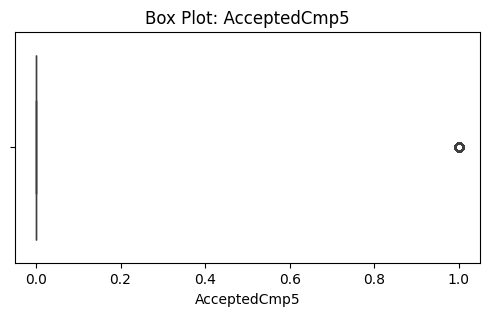

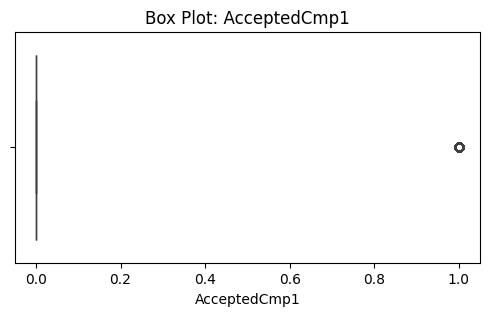

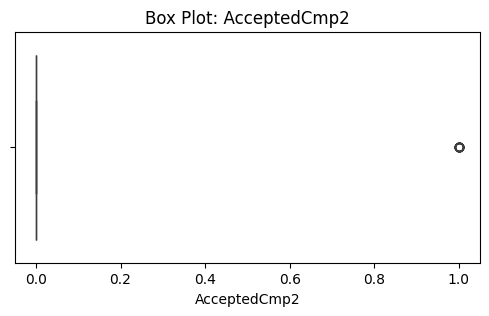

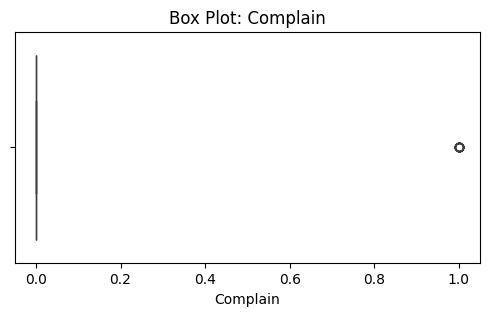

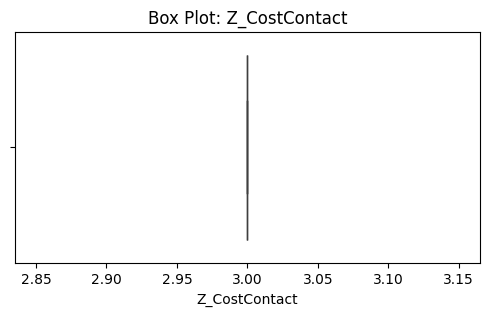

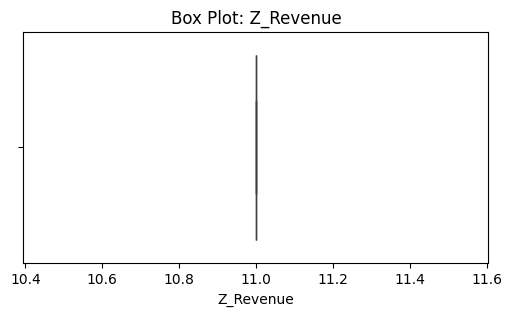

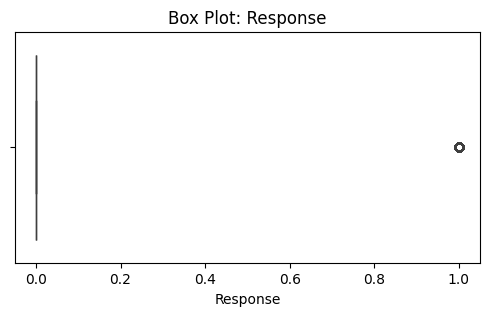

Outlier summary:
Response               334
MntSweetProducts       248
MntFruits              227
MntFishProducts        223
MntGoldProds           207
MntMeatProducts        175
AcceptedCmp4           167
AcceptedCmp3           163
AcceptedCmp5           163
AcceptedCmp1           144
NumDealsPurchases       86
MntWines                35
AcceptedCmp2            30
NumCatalogPurchases     23
Complain                21
Income                   8
NumWebVisitsMonth        8
NumWebPurchases          4
Year_Birth               3
Kidhome                  0
Recency                  0
ID                       0
Teenhome                 0
NumStorePurchases        0
Z_CostContact            0
Z_Revenue                0
dtype: int64
Total missing values after treatment: 0


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

marketing_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/AML/marketing_campaign.csv", sep=";")

print("Duplicate records:", marketing_df.duplicated().sum())

# Remove duplicates
marketing_df = marketing_df.drop_duplicates().copy()

numerical_columns = marketing_df.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = marketing_df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:")
print(numerical_columns)

print("\nCategorical features:")
print(categorical_columns)

print("\nMissing-value summary:")
print(marketing_df.isnull().sum())
# Box plots
for column in numerical_columns:
    plt.figure(figsize=(6, 3))
    sns.boxplot(x=marketing_df[column])
    plt.title(f"Box Plot: {column}")
    plt.show()
# IQR outlier summary
outlier_summary = {}
for column in numerical_columns:
    q1 = marketing_df[column].quantile(0.25)
    q3 = marketing_df[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outlier_summary[column] = (
        (marketing_df[column] < lower) |
        (marketing_df[column] > upper)
    ).sum()

print("Outlier summary:")
print(pd.Series(outlier_summary).sort_values(ascending=False))

# Missing-value treatment
for column in numerical_columns:
    marketing_df[column] = marketing_df[column].fillna(
        marketing_df[column].median()
    )

for column in categorical_columns:
    marketing_df[column] = marketing_df[column].fillna(
        marketing_df[column].mode()[0]
    )

print("Total missing values after treatment:",
      marketing_df.isnull().sum().sum())
